In [1]:
import numpy as np
import matplotlib.pyplot as plt
import xobjects as xo
import xtrack as xt
import xpart as xp
import sys
import xplt

sys.path.append('/mnt/c/muco/code')
from rcsparameters.geometry.geometry import Geometry, load_file
from rcsparameters.geometry.cell import Cell
from generate_fodo import fodo, plot_twiss, apert_1b_optics, apert_2b_optics,size_beam_diam_hor, plot_path_diff,size_beam_diam_vert,vert_apert
# from ramping_module import ramping
# from track_function import track
import json

plt.rc('axes', labelsize=12)     # fontsize of the x and y labels
plt.rc('xtick', labelsize=11)    # fontsize of the tick labels
plt.rc('ytick', labelsize=11)    # fontsize of the tick labels
plt.rc('legend', fontsize=12)    # legend fontsize

/mnt/c/muco/venv/lib/python3.11/site-packages/numpy/_core/getlimits.py:548: UserWarning: Signature b'\x00\xd0\xcc\xcc\xcc\xcc\xcc\xcc\xfb\xbf\x00\x00\x00\x00\x00\x00' for <class 'numpy.longdouble'> does not match any known type: falling back to type probe function.
This warnings indicates broken support for the dtype!
  machar = _get_machar(dtype)


Define geometry

In [2]:
file_input='/mnt/c/muco/code/class_geometry/parameter_files/para_RCS_ME.txt'
kw_geo=load_file(file_input)
kw_geo['pattern']=['BSC','BNC','BSC']
# kw_geo['bloc']=2
default_para_RCS1={
        'n_sigma':6, #Nb of sigma of beam size that the QP aperture must fit
        'sigma_delta':7e-3, #Max dispersion in energy of the beam
        'emitt_n':25e-6, #Normalized emittance
        'n_cav':380, #Total number of cavity : 700, 380, 540, 3000 
        'l_cav':1.2474, #Length of 1 cavity
        'mu': np.pi/2, #Phase advance per cell
        'apert_min':30e-3, #Min aperture size (diam) to be taken for QP
        'dx':10e-3, #Extra radius length to be taken to fit vacuum chambers
        'Bpole':1, #Max field on QP pole
    }
rcs = Cell(file_input_geo=kw_geo, file_input_opt=default_para_RCS1)
# rcs.nb_cell_arc=4
# rcs.reinit_cell()
time=0
n_slice=0
option='var_ref'
L_sxt=0.5
n_turn_rcs=55
print(rcs.nb_cell_arc)

Load json file /mnt/c/muco/code/class_geometry/parameter_files/para_RCS_ME.txt
1 bloc
geo
5.0


/mnt/c/muco/venv/lib/python3.11/site-packages/rcsparameters/geometry/geometry.py:300: UserWarning: Number of cells per arc was optimised from 10 to 6
  warnings.warn(f"Number of cells per arc was optimised from {self._nb_cell_arc} to {self.nc_best}", UserWarning)


In [3]:
rcs.length_short_insertion

np.float64(4.050149197383155)

Equivalent FODO cell

Extra per quad: 0.1677180442885541


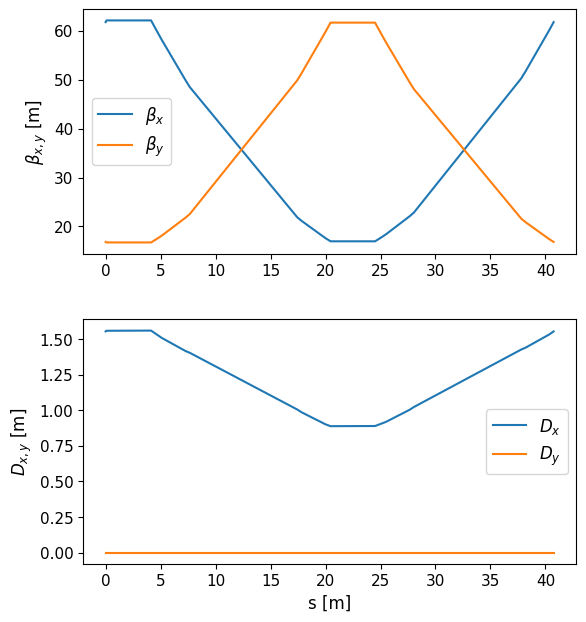

np.float64(4.050149197383155)

In [5]:
FODO_el, FODO_names, arc_el, arc_names=fodo(RCS=rcs,n_turn_rcs=n_turn_rcs, length_sxt=L_sxt, time_frac=time, option=option, n_slice=n_slice)

line_FODO=xt.Line(elements=FODO_el, element_names=FODO_names)
line_FODO.particle_ref = xp.Particles(p0c=rcs.injection_energy+(rcs.extraction_energy-rcs.injection_energy)*time, 
                                      q0=1, mass0=xp.MUON_MASS_EV)
tw_FODO=line_FODO.twiss(method='4d')
tw_init_FODO = tw_FODO.get_twiss_init('quad_f')
plot_twiss(tw_FODO)

line_FODO['quad_f'].length

In [4]:
line_tr=xt.Line(elements=arc_el, element_names=arc_names)
line_tr.particle_ref = xp.Particles(p0c=rcs.injection_energy+(rcs.extraction_energy-rcs.injection_energy)*time, 
                                    q0=1, mass0=xp.MUON_MASS_EV)

In [5]:
line_tr.elements

(Drift(length=0),
 Quadrupole(k1=0.0153, k1s=0, length=3.49, num_multipole_kicks=np.int64(0), _order=np.int64(5), inv_factorial_order=0.00833, knl=array([0., 0., 0., 0., 0., 0.]), ksl=array([0., 0., 0., 0., 0., 0.]), edge_entry_active=np.uint64(0), edge_exit_active=np.uint64(0), _sin_rot_s=-999, _cos_rot_s=-999, _shift_x=0, _shift_y=0, _shift_s=0),
 Sextupole(k2=0, k2s=0, length=0.5, _order=np.int64(5), inv_factorial_order=0.00833, knl=array([0., 0., 0., 0., 0., 0.]), ksl=array([0., 0., 0., 0., 0., 0.]), edge_entry_active=np.uint64(0), edge_exit_active=np.uint64(0), _sin_rot_s=-999, _cos_rot_s=-999, _shift_x=0, _shift_y=0, _shift_s=0, _internal_record_id=RecordIdentifier(buffer_id=np.int64(0), offset=np.int64(0))),
 Drift(length=0),
 Drift(length=0.4),
 Bend(length=1.79, k0=0.00955, k1=0, h=0.00955, model='adaptive', knl=array([0., 0., 0., 0., 0., 0.]), ksl=array([0., 0., 0., 0., 0., 0.]), edge_entry_active=np.int64(1), edge_exit_active=np.int64(1), edge_entry_model='linear', edge_exit

Working on a half-arc to match the dispersion suppressor. Working in transfer line mode 

In [7]:
line_tr.vars['kf1'] = line_tr['quad_f'].k1
line_tr.vars['kd1'] = line_tr['quad_d'].k1
line_tr.vars['kf2'] = line_tr['quad_f'].k1
line_tr.vars['kd2'] = line_tr['quad_d'].k1
line_tr.vars['kf3'] = line_tr['quad_f'].k1

line_tr.element_refs['quad_f_2'].k1 = line_tr.vars['kf1']
line_tr.element_refs['quad_f_1'].k1 = line_tr.vars['kf2']
line_tr.element_refs['quad_f'].k1 = line_tr.vars['kf3']

line_tr.element_refs['quad_d_1'].k1 = line_tr.vars['kd1']
line_tr.element_refs['quad_d'].k1 = line_tr.vars['kd2']

match_tr=line_tr.match(
            start='quad_f',
            end='marker_end', 
            init=tw_init_FODO,
            vary=xt.VaryList(['kf1','kd1','kd2','kf2','kf3'], #
                            step=1e-8,
                            tag='quad'),
            targets=[xt.TargetSet(dx=0,dpx=0,alfx=0,alfy=0, at='marker_end',tol=1e-9)], 
            method='4d',
            solve=True
            )
# match_tr.step(100)
print('RESULTS FROM TR MATCHING')
match_tr.target_status()
match_tr.vary_status()

Matching: model call n. 61               

RESULTS FROM TR MATCHING
Target status:                           
id state tag tol_met      residue  current_val target_val description                                 
 0 ON           True -2.72864e-11 -2.72864e-11          0 ('alfx', 'marker_end'), val=0, tol=1e-09 ...
 1 ON           True   1.0389e-14   1.0389e-14          0 ('alfy', 'marker_end'), val=0, tol=1e-09 ...
 2 ON           True -5.86821e-10 -5.86821e-10          0 ('dx', 'marker_end'), val=0, tol=1e-09,  ...
 3 ON           True -1.94121e-11 -1.94121e-11          0 ('dpx', 'marker_end'), val=0, tol=1e-09, ...
Vary status:                 
id state tag  met name lower_limit current_val upper_limit val_at_iter_0  step weight
 0 ON    quad OK  kf1  None          0.0163912 None            0.0152987 1e-08      1
 1 ON    quad OK  kd1  None         -0.0159814 None           -0.0152987 1e-08      1
 2 ON    quad OK  kd2  None         -0.0141419 None           -0.0152987 1e-08      1
 

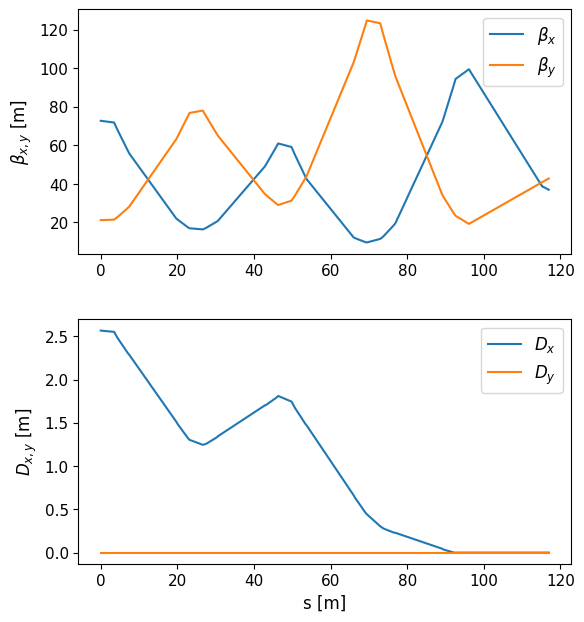

In [8]:
tw_tr=line_tr.twiss(method='4d',  
            start='quad_f',
            end='marker_end', 
            init=tw_init_FODO)
plot_twiss(tw_tr)

Creating the full arc and checking the closure of the RCS and total circumference

['sxt_f', 'drift_ext', 'drift_dd', 'BSC', 'drift_dd', 'BNC', 'drift_dd', 'BSC', 'drift_dd', 'BNC', 'drift_dd', 'BSC', 'drift_dd', 'drift_ext', 'quad_d', 'sxt_d', 'drift_ext', 'drift_dd', 'BSC', 'drift_dd', 'BNC', 'drift_dd', 'BSC', 'drift_dd', 'BNC', 'drift_dd', 'BSC', 'drift_dd', 'drift_ext', 'quad_f', 'sxt_f', 'drift_ext', 'drift_dd', 'BSC', 'drift_dd', 'BNC', 'drift_dd', 'BSC', 'drift_dd', 'BNC', 'drift_dd', 'BSC', 'drift_dd', 'drift_ext', 'quad_d', 'sxt_d', 'drift_ext', 'drift_dd', 'BSC', 'drift_dd', 'BNC', 'drift_dd', 'BSC', 'drift_dd', 'BNC', 'drift_dd', 'BSC', 'drift_dd', 'drift_ext', 'quad_f', 'drift_ext', 'drift_ins', 'cavity', 'RF_acc', 'quad_d_half', 'marker_end']
['drift_ext', 'quad_f', 'sxt_f', 'drift_ext', 'drift_dd', 'BSC', 'drift_dd', 'BNC', 'drift_dd', 'BSC', 'drift_dd', 'BNC', 'drift_dd', 'BSC', 'drift_dd', 'drift_ext', 'quad_d', 'sxt_d', 'drift_ext', 'drift_dd', 'BSC', 'drift_dd', 'BNC', 'drift_dd', 'BSC', 'drift_dd', 'BNC', 'drift_dd', 'BSC', 'drift_dd', 'drift_ext'

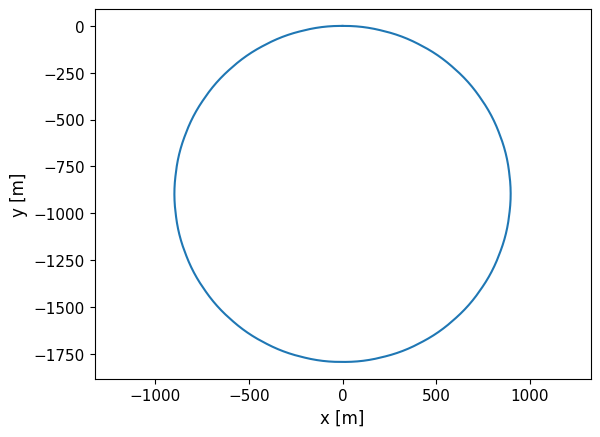

SURVEY RESULTS
X final -2.6328993469193083e-06
Z final 0.06871766152366021
s total 5637.599262664264
Circumference 5990
Theta/2pi final -1.0000121959883337


In [6]:
tr=arc_el[2:]
tot_arc_el=tr[::-1]+arc_el
tr_name=arc_names[2:]
tot_arc_names=tr_name[::-1]+arc_names
print(tr_name)
print(arc_names)
line_tot=xt.Line(elements=tot_arc_el*rcs.nb_arc, element_names=tot_arc_names*rcs.nb_arc)
line_tot.particle_ref = xp.Particles(p0c=rcs.injection_energy+(rcs.extraction_energy-rcs.injection_energy)*time, q0=1, mass0=xp.MUON_MASS_EV)
line_tot.build_tracker()
survey=line_tot.survey()
plt.figure()
plt.plot(survey['Z'], survey['X'])
plt.axis('equal')
# for i, el in enumerate(line.element_names):
#     if 'dip' in el:
#         plt.axvline(x=survey['Z'][i], color='grey', linestyle='--')
#     elif 'quad' in el:
#         plt.axvline(x=survey['Z'][i], color='red', linestyle='--')
plt.xlabel('x [m]')
plt.ylabel('y [m]')
plt.show()
print('SURVEY RESULTS')
print('X final', survey['X'][-1])
print('Z final', survey['Z'][-1])
print('s total', survey['s'][-1])
print('Circumference', rcs.circumference)
print('Theta/2pi final', survey['theta'][-1]/np.pi/2)

Creating the line of an arc

In [10]:
line_ds=xt.Line(elements=tot_arc_el, element_names=tot_arc_names)
line_ds.particle_ref = xp.Particles(p0c=rcs.injection_energy+(rcs.extraction_energy-rcs.injection_energy)*time, q0=1, mass0=xp.MUON_MASS_EV)
tab_ds=line_ds.get_table()

Repetition found in `element_names` -> renaming


Matching the dispersion suppressor on the arc from the transfer line results

In [11]:
line_ds.vars['kf1'] = line_tr['quad_f_2'].k1
line_ds.vars['kd1'] = line_tr['quad_d_1'].k1
line_ds.vars['kf2'] = line_tr['quad_f_1'].k1
line_ds.vars['kd2'] = line_tr['quad_d'].k1
line_ds.vars['kf3'] = line_tr['quad_f'].k1

line_ds.element_refs['quad_f_4'].k1 = line_ds.vars['kf1']
# line_ds.element_refs['quad_f'].k1 = line_ds.vars['kf1']
line_ds.element_refs['quad_f_3'].k1 = line_ds.vars['kf2']
# line_ds.element_refs['quad_f_2'].k1 = line_ds.vars['kf2']
line_ds.element_refs['quad_f_2'].k1 = line_ds.vars['kf3']
# line_ds.element_refs['quad_f_3'].k1 = line_ds.vars['kf3']

line_ds.element_refs['quad_d_3'].k1 = line_ds.vars['kd1']
# line_ds.element_refs['quad_d'].k1 = line_ds.vars['kd1']
line_ds.element_refs['quad_d_2'].k1 = line_ds.vars['kd2']
# line_ds.element_refs['quad_d_1'].k1 = line_ds.vars['kd2']

match_ds=line_ds.match(
                vary=xt.VaryList(['kf1','kd1','kd2','kf2','kf3'],
                                step=1e-8,
                                tag='quad'),
                targets=[
                    xt.TargetSet(dx=0, at='marker_end',tol=1e-9),
                        ],
                method='6d',
                matrix_stability_tol=0.05,
                solve=True
                )
# match_ds.step(100)
print('RESULTS FROM DS MATCHING')
match_ds.target_status()
match_ds.vary_status()

tw_ds=line_ds.twiss(method='6d', matrix_stability_tol=0.05)

Matching: model call n. 28               

RESULTS FROM DS MATCHING
Target status:                           
id state tag tol_met      residue  current_val target_val description                                 
 0 ON           True -1.50902e-10 -1.50902e-10          0 ('dx', 'marker_end'), val=0, tol=1e-09,  ...
Vary status:                 
id state tag  met name lower_limit current_val upper_limit val_at_iter_0  step weight
 0 ON    quad OK  kf1  None          0.0167399 None            0.0163912 1e-08      1
 1 ON    quad OK  kd1  None         -0.0160456 None           -0.0159814 1e-08      1
 2 ON    quad OK  kd2  None         -0.0137756 None           -0.0141419 1e-08      1
 3 ON    quad OK  kf2  None          0.0199806 None            0.0197879 1e-08      1
 4 ON    quad OK  kf3  None          0.0172529 None            0.0163186 1e-08      1


Matching: model call n. 20               

RESULTS FROM TR MATCHING
Target status:                           
id state tag    tol_met     residue current_val target_val description                             
 0 ON    chroma    True 1.72853e-07    0.192308   0.192308 'dqx', val=0.192308, tol=1e-06, weight=1
 1 ON    chroma    True 9.45841e-12    0.192308   0.192308 'dqy', val=0.192308, tol=1e-06, weight=1
Vary status:                 
id state tag met name lower_limit current_val upper_limit val_at_iter_0  step weight
 0 ON    sxt OK  sf   None           0.157051 None            0.0804296 1e-06      1
 1 ON    sxt OK  sd   None          -0.248927 None            0.0786667 1e-06      1


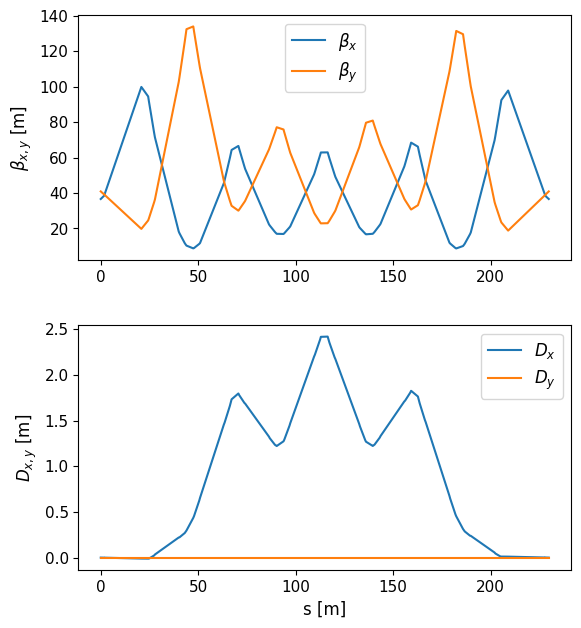

In [12]:
line_ds.vars['sf'] = line_ds['quad_f_1'].k1*line_ds['quad_f_1'].length/tw_ds['dx','quad_f_1']/line_ds['sxt_f'].length
line_ds.vars['sd'] = -line_ds['quad_d_1'].k1*line_ds['quad_d_1'].length/tw_ds['dx','quad_d_1']/line_ds['sxt_d'].length

for sxt in tab_ds.rows[tab_ds.element_type=='Sextupole'].name:
    if 'sxt_d' in sxt:
        line_ds.element_refs[sxt].k2 = line_ds.vars['sd']
    elif 'sxt_f' in sxt:
        line_ds.element_refs[sxt].k2 = line_ds.vars['sf']
    
chroma_goal=5/rcs.nb_arc

match_ds_chroma=line_ds.match(
                vary=xt.VaryList(['sf','sd'], 
                                step=1e-6,
                                tag='sxt'),
                targets=[
                    xt.TargetSet(dqx=chroma_goal, dqy=chroma_goal, tol=1e-6, tag='chroma')
                    ],
                method='6d',
                matrix_stability_tol=0.05,
                solve=True
                )
print('RESULTS FROM TR MATCHING')
match_ds_chroma.target_status()
match_ds_chroma.vary_status()

tw_ds=line_ds.twiss(method='6d', matrix_stability_tol=0.05)
plot_twiss(tw_ds)

Printing some global parameters: dipole lengths, dipole aperture, qp aperture, path length difference ....

In [13]:
tab=line_ds.get_table()
quad_k1=[]
sxt_k2=[]
for quad in tab.rows[tab.element_type == 'Quadrupole'].name:
    print(quad, line_ds[quad].k1)
    quad_k1.append(line_ds[quad].k1)
for sxt in tab.rows[tab.element_type == 'Sextupole'].name:
    print(sxt, line_ds[sxt].k2)
    sxt_k2.append(line_ds[sxt].k2)
print(max(np.absolute(quad_k1)), max(np.absolute(sxt_k2)))

quad_d_half -0.015298698653121138
quad_f 0.016739885462277723
quad_d -0.016045646072880882
quad_f_1 0.019980581259370522
quad_d_1 -0.013775591745504646
quad_f_2 0.017252948453317807
quad_d_2 -0.013775591745504646
quad_f_3 0.019980581259370522
quad_d_3 -0.016045646072880882
quad_f_4 0.016739885462277723
quad_d_half_1 -0.015298698653121138
sxt_d -0.24892718596723812
sxt_f 0.15705058195647262
sxt_d_1 -0.24892718596723812
sxt_f_1 0.15705058195647262
sxt_d_2 -0.24892718596723812
sxt_f_2 0.15705058195647262
sxt_d_3 -0.24892718596723812
0.019980581259370522 0.24892718596723812


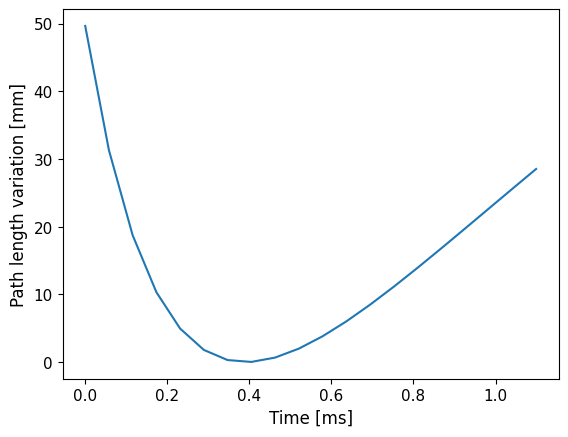

GLOBAL PARAMETER
C 5990
NB arc 26
Nb of cells per arc 4
Cell length 53.038346153846156
Longueur totale NC 2539.194413165309
Longueur totale SC 1114.7689928206817
FF arc 0.921
Dipole FF 0.610011
MCF 0.001171
Qs 0.349
Qx 33.117
Qy 23.144
dqx 5.0
dqy 5.0
pattern ['BSC', 'BNC', 'BSC']
Max path length diff 49.6 mm
Relative path length diff 8.29 e-6
Traj excursion SC 26.0 mm
Hor apert SC 87.0 mm
Length SC 2.68 m
Traj excursion NC 71.0 mm
Hor apert NC 132.0 mm
Length NC 12.21 m
Horizontal beam size 40.5 mm
Vertical beam size 12.7 mm
Vertical aperture 32.7 mm
Length QP 3.49 m
QP Bpole for 50mm apert 1.25 T
Extra length QP 0.0 m
Length SXT 0.5 m
SXT Bpole for 50mm apert 0.19 T


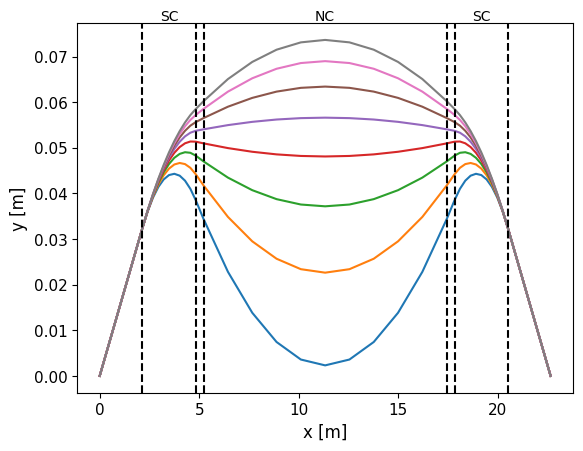

In [14]:
delta = 6.1e-3
max_path_diff=plot_path_diff(rcs, n_turn_rcs)
hor_size_beam=size_beam_diam_hor(tw_ds, rcs,delta)
vert_size_beam=size_beam_diam_vert(tw_ds, rcs,delta)
apert_V=vert_apert(tw_ds, rcs,delta)
print('GLOBAL PARAMETER')
print('C', rcs.circumference)
print('NB arc', rcs.nb_arc)
print('Nb of cells per arc', rcs.nb_cell_arc)
print('Cell length', rcs.cell_length)
print('Longueur totale NC', rcs.dipole_families['BNC']['tot_length'])
if rcs.type == 'hybrid':
    print('Longueur totale SC', rcs.dipole_families['BSC']['tot_length'])
print('FF arc', np.round(rcs.filling_ratio,3))
print('Dipole FF', np.round(rcs.filling_ratio_dipole,6))
print('MCF', round(tw_ds['momentum_compaction_factor'], 6))
print('Qs', round(tw_ds['qs']*rcs.nb_arc, 3))
print('Qx', round(tw_ds['qx']*rcs.nb_arc, 3))
print('Qy', round(tw_ds['qy']*rcs.nb_arc, 3))
print('dqx', round(tw_ds['dqx']*rcs.nb_arc, 2))
print('dqy', round(tw_ds['dqy']*rcs.nb_arc, 2))
print('pattern', rcs.pattern)
if rcs.type == 'hybrid':
    print('Max path length diff', round(max_path_diff*1e3,1), 'mm')
    print('Relative path length diff', round(max_path_diff/rcs.circumference*1e6,2), 'e-6')
    print('Traj excursion SC', round(rcs.width_sc_opt*1e3,0), 'mm')
    print('Hor apert SC', round((rcs.width_sc_opt+hor_size_beam+2*rcs.dx_qp)*1e3,0), 'mm')
    # print('Apert SC', round(rcs.aperture_sc_opt*1e3,0), 'mm')
    print('Length SC', round(rcs.dipole_families['BSC']['length'],2), 'm')
    print('Traj excursion NC', round(rcs.width_nc_opt*1e3,0), 'mm')
    # print('Apert NC', round(rcs.aperture_nc_opt*1e3,0), 'mm')
    print('Hor apert NC', round((rcs.width_nc_opt+hor_size_beam+2*rcs.dx_qp)*1e3,0), 'mm')
print('Length NC', round(rcs.dipole_families['BNC']['length'],2), 'm')
print('Horizontal beam size', round(hor_size_beam*1e3,1), 'mm')
print('Vertical beam size', round(vert_size_beam*1e3,1), 'mm')
print('Vertical aperture', round(apert_V*1e3,1), 'mm')
print('Length QP', round(line_ds['quad_d'].length,2), 'm')
print('QP Bpole for 50mm apert', round(max(np.absolute(quad_k1))*rcs.ext_Brho*(25e-3),2), 'T')
print('Extra length QP', round(line_ds['drift_ext'].length*2,2), 'm')
print('Length SXT', round(line_ds['sxt_d'].length,2), 'm')
print('SXT Bpole for 50mm apert', round(max(np.absolute(sxt_k2))/2*rcs.ext_Brho*(25e-3)**2,2), 'T')

rcs.plot_traj()

In [15]:
rcs.path_length_tot(0)

np.float64(4711.997448738296)

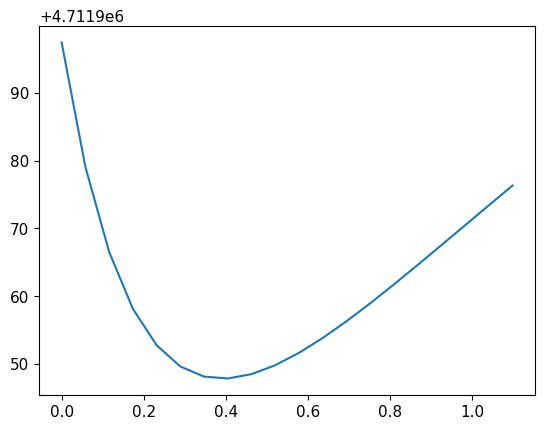

In [16]:
t_geo_path=np.linspace(0,1,20)
path_length_geo=[]
for t in t_geo_path:
    path_length_geo.append(rcs.path_length_tot(t))
plt.figure()
plt.plot(t_geo_path*rcs.circumference*n_turn_rcs/(3.0e8)*1e3, np.array(path_length_geo)*1e3)

In [17]:
rcs.path_length_min

np.float64(4711.947805562586)

In [18]:
rcs.mcf

np.float64(0.0016105571754753542)

In [19]:
# line_ds.to_json('/mnt/c/muco/code/lattice/RCS2_DS_inj_highmu.json')
# para = {  "type": rcs.type,
#    "circumference": rcs.circumference,
#    "injection_energy": rcs.injection_energy,
#    "extraction_energy": rcs.extraction_energy,
#    "length_short_insertion": rcs.length_short_insertion,
#    "dipole_spacing": rcs.dipole_spacing,
#    "nb_RF_section": rcs.nb_RF_section,
#    "nb_arc": rcs.nb_arc,
#    "nb_cell_arc": rcs.nb_cell_arc,
#    "dipoles": rcs.dipoles,
#    "filling_ratio": rcs.filling_ratio,
#    "filling_ratio_RF": rcs.filling_ratio_RF,
#    "pattern": rcs.pattern
# }
# with open('para_RCS2_opt_highmu.json', 'w') as file:
#     json.dump(para, file,indent=4)